In [50]:
from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
DATA_DIR = ROOT / "data" / "raw" / "seg_train"

In [51]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True,
    validation_split=0.3,
    subset="training",
    seed=42
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True,
    validation_split=0.3,
    subset="validation",
    seed=42
)

val_ds = temp_ds.take(len(temp_ds) // 2)
test_ds = temp_ds.skip(len(temp_ds) // 2)

Found 17034 files belonging to 6 classes.
Using 11924 files for training.
Found 17034 files belonging to 6 classes.
Using 5110 files for validation.


In [52]:
print(train_ds.class_names)

for images, labels in train_ds.take(1):
    print(images.shape)
    print(labels.shape)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
(32, 150, 150, 3)
(32,)


In [53]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda images, labels: (normalization_layer(images), labels))
val_ds = val_ds.map(lambda images, labels: (normalization_layer(images), labels))
test_ds = test_ds.map(lambda images, labels: (normalization_layer(images), labels))

In [54]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Min pixel value:", tf.reduce_min(images).numpy())
    print("Max pixel value:", tf.reduce_max(images).numpy())

Images shape: (32, 150, 150, 3)
Labels shape: (32,)
Min pixel value: 0.0
Max pixel value: 1.0


In [55]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomContrast(0.1),
])

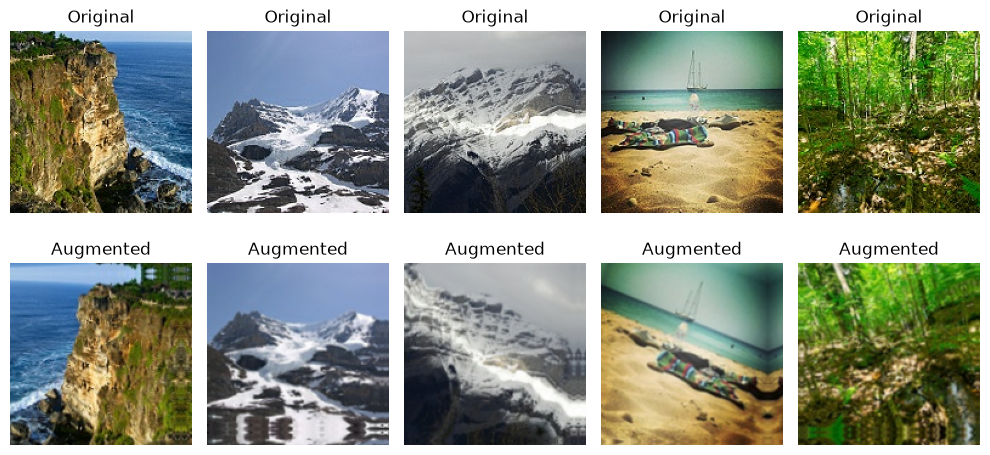

In [56]:
import matplotlib.pyplot as plt

# Get one batch of normalized images
images, labels = next(iter(train_ds))

# Apply augmentation to the batch
augmented_images = data_augmentation(images, training=True)

plt.figure(figsize=(10, 5))

for i in range(5):
    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy())
    plt.axis("off")
    plt.title("Original")

    # Augmented image
    plt.subplot(2, 5, i + 6)
    plt.imshow(tf.clip_by_value(augmented_images[i], 0, 1).numpy())
    plt.axis("off")
    plt.title("Augmented")

plt.tight_layout()
plt.show()

In [57]:
train_ds = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True), labels)
)